In [42]:
import random
import numpy as np
import matplotlib.pyplot as plt

# Punto 1

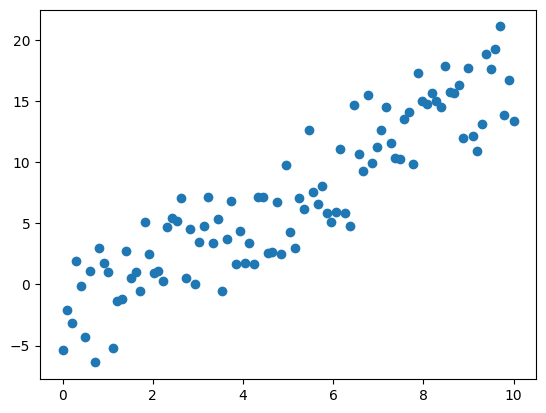

In [43]:
def formula(x, m, b, noise=10):
  return x*m + b + (random.random()-0.5)*noise

m = 2
b = -3

X_0 = np.linspace(0, 10, 100)
Y_0 = [formula(x,m,b) for x in X_0]
plt.scatter(X_0,Y_0)

In [44]:
a,b = random.uniform(1,11), random.uniform(1,11)
def error_lineal(a,b):
  error = 0
  imagenes = [None]*len(X_0)
  sumas = []
  for i in range(len(X_0)):
    imagen_x = a*(X_0[i]) + b
    imagenes[i] = (imagen_x)

  for j in range(len(Y_0)):
    dif = (imagenes[j] - Y_0[j])**2
    sumas.append(dif)
    l = sum(sumas)
  return l

def comparar_lineal(a, b):
  error_actual = error_lineal(a, b)

  lista_aux = [a, b]

  while True:
    errores = []

    for i in range(len(lista_aux)):
      lista_mas = lista_aux.copy()
      lista_mas[i] += 0.1
      errores.append((error_lineal(*lista_mas), lista_mas))

      lista_menos = lista_aux.copy()
      lista_menos[i] -= 0.1
      errores.append((error_lineal(*lista_menos), lista_menos))

    mejor = min(errores)

    if abs(mejor[0] - error_actual) < 1:
      break

    error_actual = mejor[0]
    lista_aux = mejor[1]

  return mejor
comparar_lineal(1,2)

(np.float64(766.3978433590819), [1.8000000000000007, -1.9000000000000015])

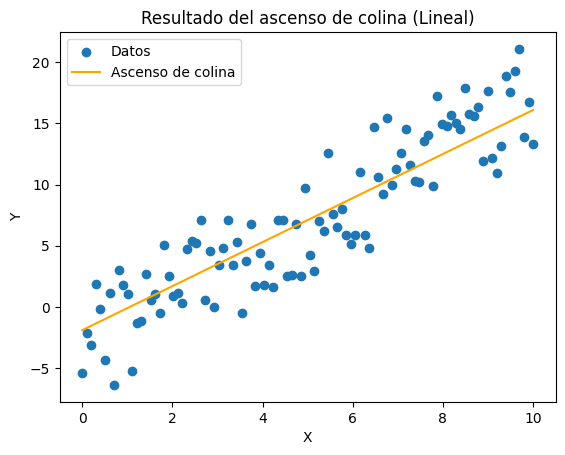

In [45]:
def graficar_comparar_lineal(a, b):
  resultado = comparar_lineal(a, b)

  valores = resultado[1]

  a = valores[0]
  b = valores[1]
  imagenes = []

  for x in X_0:
    imagenes.append(a*x + b)

  plt.scatter(X_0, Y_0, label="Datos")
  plt.plot(X_0, imagenes, label="Ascenso de colina", color="orange")
  plt.xlabel("X")
  plt.ylabel("Y")
  plt.title("Resultado del ascenso de colina (Lineal)")
  plt.legend()
  plt.show()
graficar_comparar_lineal(2,4)

# punto 2

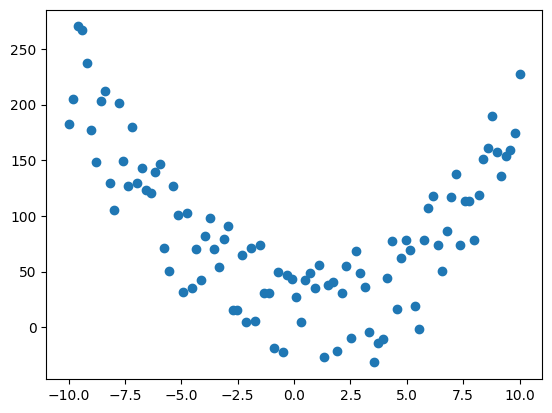

In [46]:
def formula(x, a, b, c, noise=115):
  return (x**2)*a+ x*b + c + (random.random()-0.5)*noise

a = 2
b = -3
c = 10

X_1= np.linspace(-10, 10, 100)
Y_1 = [formula(x,a,b,c) for x in X_1]
plt.scatter(X_1,Y_1)

In [47]:
a,b,c = random.uniform(1,11), random.uniform(1,11), random.uniform(1,11)
def error_cuadratico(a,b,c):
  error = 0
  imagenes = [None]*len(X_1)
  sumas = []
  for i in range(len(X_1)):
    imagen_x = a*(X_1[i])**2 + b*(X_1[i]) + c
    imagenes[i] = (imagen_x)

  for j in range(len(Y_1)):
    dif = (imagenes[j] - Y_1[j])**2
    sumas.append(dif)
    l = sum(sumas)
  return l

def comparar_cuadratico(a, b, c):
  error_actual = error_cuadratico(a, b, c)

  lista_aux = [a, b, c]

  while True:
    errores = []

    for i in range(len(lista_aux)):
      lista_mas = lista_aux.copy()
      lista_mas[i] += 0.1
      errores.append((error_cuadratico(*lista_mas), lista_mas))

      lista_menos = lista_aux.copy()
      lista_menos[i] -= 0.1
      errores.append((error_cuadratico(*lista_menos), lista_menos))

    mejor = min(errores)

    if abs(mejor[0] - error_actual) < 1:
      break

    error_actual = mejor[0]
    lista_aux = mejor[1]

  return mejor
comparar_cuadratico(1,2,3)

(np.float64(100718.28957807402),
 [2.000000000000001, -2.900000000000002, 18.699999999999996])

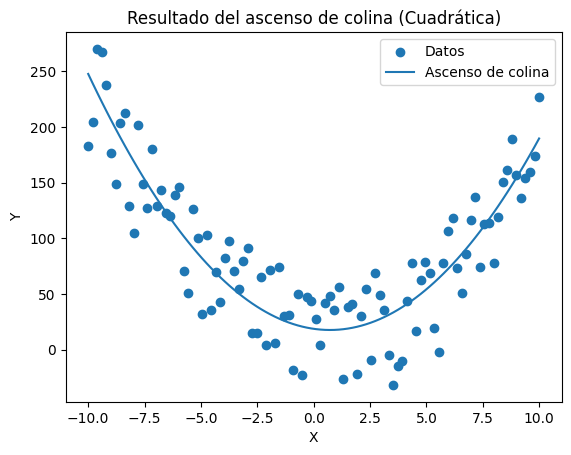

In [48]:
def graficar_comparar_cuadratico(a, b, c):
  resultado = comparar_cuadratico(a, b, c)

  valores = resultado[1]

  a = valores[0]
  b = valores[1]
  c = valores[2]
  imagenes = []

  for x in X_1:
    imagenes.append(a*x**2 + b*x + c)

  plt.scatter(X_1, Y_1, label="Datos")
  plt.plot(X_1, imagenes, label="Ascenso de colina")

  plt.xlabel("X")
  plt.ylabel("Y")
  plt.title("Resultado del ascenso de colina (Cuadrática)")
  plt.legend()
  plt.show()
graficar_comparar_cuadratico(2,4,1)

# Punto 3

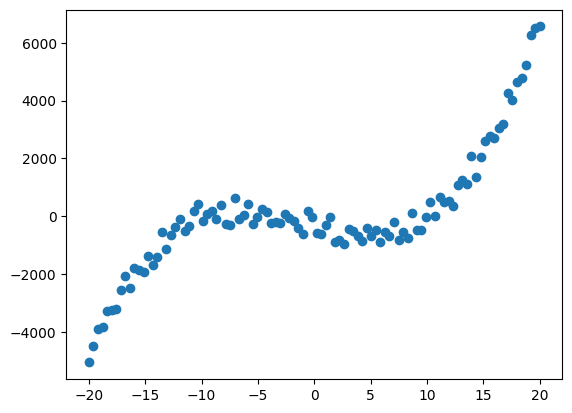

In [49]:
def formula(x, a, b, c, noise=10):
  return (x-a)*(x-b)*(x-c) + (random.random()-0.5)*noise

a = 10
b = -3
c = -10

X = np.linspace(-20, 20, 100)
Y = [formula(x,a,b,c, noise=1000) for x in X]
plt.scatter(X,Y)

In [50]:
a,b,c = random.uniform(-11,11), random.uniform(-11,11), random.uniform(-11,11)
def error_cubico(a,b,c):
  imagenes = [None]*len(X)
  sumas = []
  for i in range(len(X)):
    imagen_x = (X[i] - a)*(X[i] - b)*(X[i] - c)
    imagenes[i] = imagen_x

  for j in range(len(Y)):
    dif = (imagenes[j] - Y[j])**2
    sumas.append(dif)
  return sum(sumas)

def comparar_cubico(a, b, c):
  error_actual = error_cubico(a, b, c)
  lista_aux = [a, b, c]

  while True:
    errores = []
    for i in range(len(lista_aux)):
      lista_mas = lista_aux.copy()
      lista_mas[i] += 0.1
      errores.append((error_cubico(*lista_mas), lista_mas))

      lista_menos = lista_aux.copy()
      lista_menos[i] -= 0.1
      errores.append((error_cubico(*lista_menos), lista_menos))

    mejor = min(errores)
    if mejor[0] >= error_actual or abs(mejor[0] - error_actual) < 10:
      break
    error_actual = mejor[0]
    lista_aux = mejor[1]

  return mejor
comparar_cubico(1, 2, 3)

(np.float64(7296072.791949516),
 [-9.89999999999998, -3.800000000000003, 10.29999999999998])

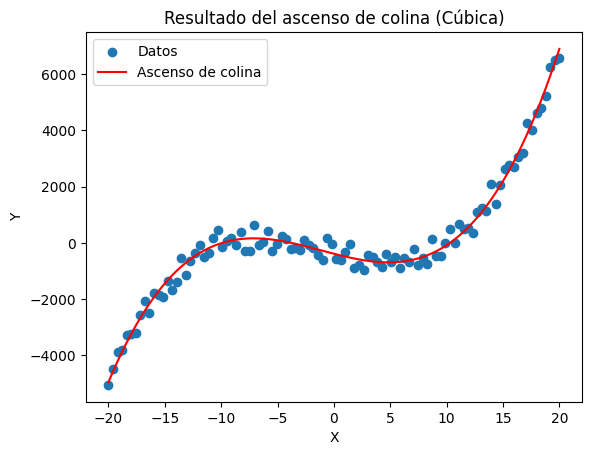

In [51]:
def graficar_comparar_cubico(a, b, c):
  resultado = comparar_cubico(a, b, c)
  valores = resultado[1]

  a= valores[0]
  b = valores[1]
  c = valores[2]
  imagenes = []

  for x in X:
    imagenes.append((x - a)*(x - b)*(x - c))

  plt.scatter(X, Y, label="Datos")
  plt.plot(X, imagenes, label="Ascenso de colina", color="red")
  plt.xlabel("X")
  plt.ylabel("Y")
  plt.title("Resultado del ascenso de colina (Cúbica)")
  plt.legend()
  plt.show()
graficar_comparar_cubico(1, 2, 3)